# How-to 4 · Periodograms

`PeriodicityDetector` on (a) a scalar RV series: GLS, PDC and the error-aware PDC with
local p-value levels; (b) a series of spectra: USuRPER and the partial *shift* / *shape*
periodograms.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sparta import Observations, TimeSeries
from sparta.instruments import Simulation
from sparta.instruments.simulated import component_templates
from sparta.plotting import apply_style

apply_style()        # SPARTA figure style: data black, model red, extra blue, maps grey

# Period of the highest peak of a stored periodogram
def best_period(detector, key):
    """Period (days) of the highest peak of a stored periodogram."""
    f, p = detector.results_frequency[key], detector.results_power[key]
    return 1 / f[np.argmax(p)]

## (a) A scalar series: 40 RVs of a 7.3-day orbit with very unequal error bars

In [2]:
# 40 random epochs of a 7.3-day sinusoid, with very unequal error bars
rng = np.random.default_rng(1)
t = np.sort(rng.uniform(0, 100, 40))                     # days
P = 7.3
err = rng.exponential(1.0, t.size)                       # km/s
rv = np.sin(2 * np.pi * t / P) + err * rng.standard_normal(t.size)

# Put the RV series in an Observations object
obs = Observations(time_series=TimeSeries(times=t, vals=list(rv), errors=list(err)))
# Set the frequency range and grid of the search
obs.init_periodicity_detector(freq_range=(0.01, 1.0), periodogram_grid_resolution=2000)  # 1/day
pd = obs.periodicity_detector
# Three periodograms of the same series
pd.calc_gls()                  # unweighted: GLS here ignores the error bars
pd.calc_pdc()                  # 'PDC_unbiased'
pd.calc_pdc(errors=True)       # 'PDC_errors_unbiased': each point weighted by its error bar
# The strongest peak of each, to compare with the true 7.3 d
for key in ("GLS", "PDC_unbiased", "PDC_errors_unbiased"):
    print(f"{key:20s}: best period {best_period(pd, key):.3f} d")

GLS                 : best period 1.820 d
PDC_unbiased        : best period 7.299 d
PDC_errors_unbiased : best period 7.273 d


power levels of p = 1e-2, 1e-4: [0.141 0.353]
local p-value of the error-aware PDC peak: 2.0e-04


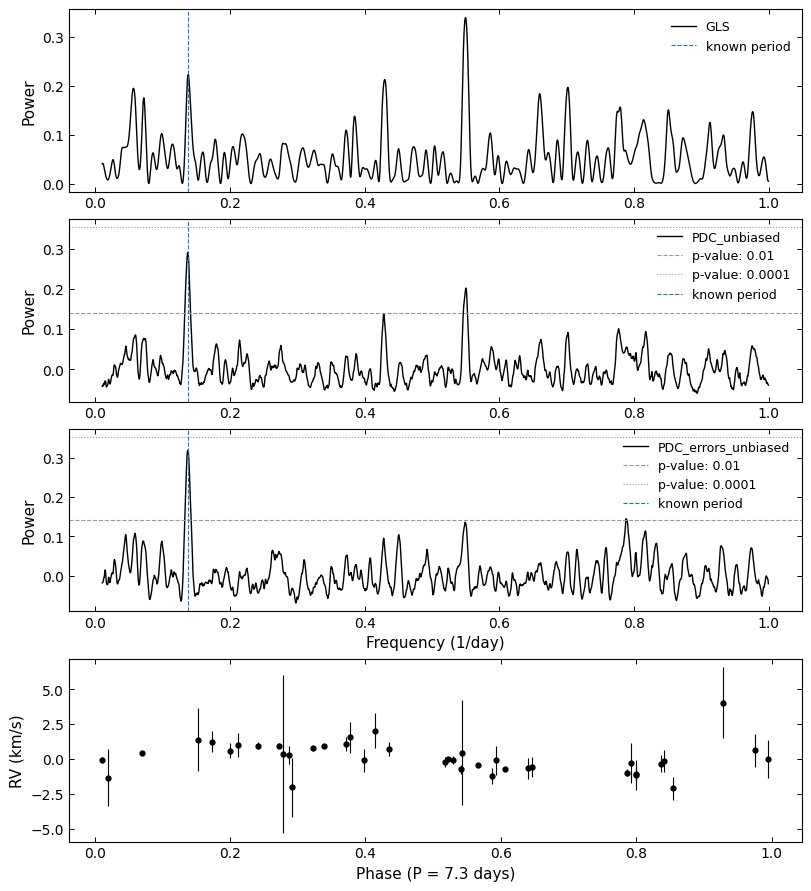

In [3]:
# Local p-value levels, and the p-value of the error-aware PDC peak
pvals = [1e-2, 1e-4]                                     # local (single-frequency) p-values
peak = pd.results_power["PDC_errors_unbiased"].max()
print("power levels of p = 1e-2, 1e-4:", np.round(pd.calc_pdc_pval(pvals, inverse_sf=True), 3))
print(f"local p-value of the error-aware PDC peak: {pd.calc_pdc_pval([peak])[0]:.1e}")

pd.period_truth = [P]                                    # marked in blue; folds the value panel
# The periodograms with the p-value levels, and the RVs folded at the true period
fig = pd.plot_periodograms(plot_vals=True, annotate_pval=pvals, figsize=(8, 2.2))
plt.show()

## (b) Spectra: a star on a 7.3-day orbit plus a faint companion on a 3.1-day orbit

USuRPER needs no template or RVs. The partial periodograms split the signal into Doppler
*shifts* and line-*shape* changes, given one RV per epoch.

In [4]:
# The star's orbit (7.3 d) and a faint companion's (3.1 d)
P1, P2 = 7.3, 3.1                                         # days
v1 = 30.0 * np.sin(2 * np.pi * t / P1)                    # km/s
v2 = v1 + 20.0 + 15.0 * np.sin(2 * np.pi * t / P2)
# Simulate HARPS-like spectra of both stars
sim = Simulation(like="HARPS", windows_A=[(5000, 5100)], times=t, rv_kms=np.column_stack([v1, v2]),
                 components=[dict(teff=5800, logg=3.5, feh=0.5, vsini=3.0, amplitude=1.0),
                             dict(teff=4900, logg=4.5, vsini=2.0, amplitude=0.15)],
                 snr=100, noise="constant", seed=7)
# Load them, and measure one RV per epoch against the primary's template
spec_obs = Observations(survey="SIMULATED", simulation=sim)
spec_obs.calc_rv_against_template(component_templates(sim)[0], dv=0.1, vel_bound=60)

# Set the frequency range and grid of the search
spec_obs.init_periodicity_detector(freq_range=(0.01, 1.0), periodogram_grid_resolution=2000)
spd = spec_obs.periodicity_detector
# USuRPER works on the spectra alone; the partial periodograms also use the RVs
spd.calc_usurper()                                        # 'USURPER_unbiased'
spd.calc_partial_periodogram("shift")                     # 'partial_shift'
spd.calc_partial_periodogram("shape")                     # 'partial_shape'
# The strongest peak of each
for key in ("USURPER_unbiased", "partial_shift", "partial_shape"):
    print(f"{key:16s}: best period {best_period(spd, key):.3f} d")

USURPER_unbiased: best period 7.299 d
partial_shift   : best period 7.299 d
partial_shape   : best period 3.096 d


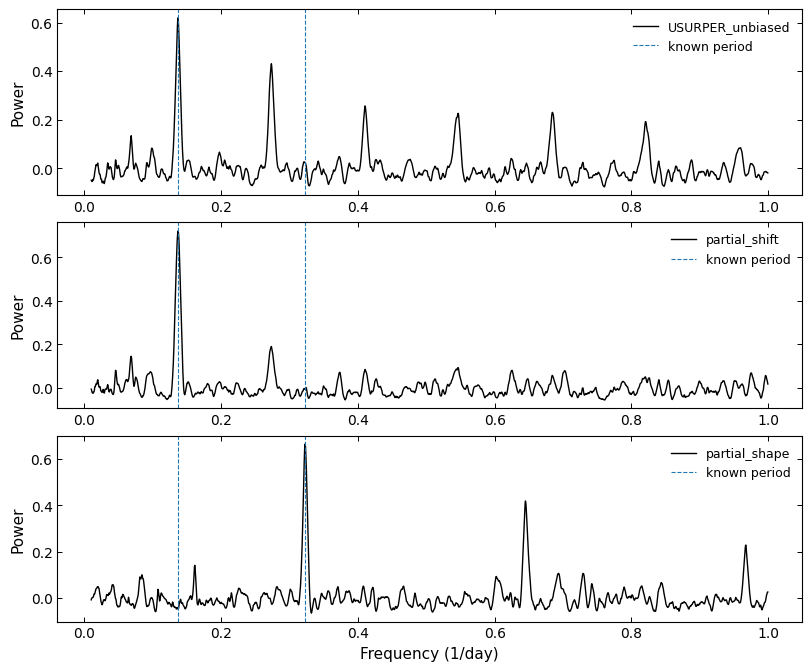

In [5]:
# Mark the two true periods in the figure
spd.period_truth = [P1, P2]
fig = spd.plot_periodograms(figsize=(8, 2.2))
plt.show()

## Go deeper

- Each periodogram built from the `sparta.pdc` atoms: tutorials [`06_pdc`](../tutorials/06_pdc.ipynb), [`07_usurper`](../tutorials/07_usurper.ipynb) and [`08_partial_pdc`](../tutorials/08_partial_pdc.ipynb).
- Definitions, result keys and units: [periodograms](../../docs/periodograms.md).
- What the p-values mean (local, one frequency): [periodograms § p-values](../../docs/periodograms.md#p-values).
- Known limits: [limitations § periodograms](../../docs/limitations.md#periodograms).
- The checklist before claiming a period: [good practices](../../docs/good_practices.md#periodograms).